# Pipeline sur données réelles : New York (entraînement) → Nabeul 2018 (validation)

Ce notebook reprend tout le pipeline avec des **données réelles**, dans sa version optimisée :

- **Entraînement et test** : 311 inondations de rue à New York (Southeast Queens, 2020–2026), pluie **mesurée** aux stations JFK et LaGuardia, **154 212 avaloirs** officiels (NYC DEP), routes OpenStreetMap, terrain nu USGS 3DEP 10 m, ESA WorldCover.
- **Validation de transfert** : crue éclair du 22 septembre 2018 au Cap Bon (Copernicus EMS EMSR319).

Scripts : `flood_risk/real/nyc.py`, `flood_risk/tune.py`, `flood_risk/train.py`, `flood_risk/real/drainage_test.py`, `flood_risk/real/nabeul.py`.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mp
from IPython.display import Image, display
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

from flood_risk.schema import RAW_FEATURES, HISTORY_FEATURES, LABEL
from flood_risk.features import engineer
from flood_risk.train import budget_recall
from flood_risk import v1, v2

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def draw_flow(labels, title, figsize=(16, 3.2)):
    colors = ["#dbeafe", "#e0f2fe", "#dcfce7", "#fef9c3", "#fde68a", "#fbcfe8", "#e9d5ff", "#fee2e2"]
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off"); ax.set_xlim(0, len(labels) * 2); ax.set_ylim(0, 2)
    for i, lab in enumerate(labels):
        x = i * 2 + 0.1
        ax.add_patch(mp.FancyBboxPatch((x, 0.45), 1.7, 1.3, boxstyle="round,pad=0.02,rounding_size=0.12",
                                       fc=colors[i % len(colors)], ec="#334155"))
        ax.text(x + 0.85, 1.1, lab, ha="center", va="center", fontsize=9)
        if i < len(labels) - 1:
            ax.annotate("", xy=(x + 2.0, 1.1), xytext=(x + 1.75, 1.1),
                        arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#334155"))
    ax.set_title(title, fontsize=12, weight="bold")
    plt.tight_layout(); plt.show()

draw_flow(["Sources\nouvertes", "Segments\nOSM 150 m", "Terrain 10 m\n+ béton\n+ avaloirs", "Orages\n(pluie mesurée)",
           "Étiquettes\n+ historique\n311", "Tuning\npar orage", "Test\norages inconnus", "Transfert\nNabeul 2018"],
          "Schéma du pipeline réel")

## 1. Sources

| Donnée | Source | Rôle |
|---|---|---|
| Inondations de rue | NYC 311 (« Street Flooding », « Flooding on Street », « Highway Flooding ») | étiquette, historique |
| Avaloirs bouchés | NYC 311 « Catch Basin Clogged/Flooding » | état du drainage (avant l'orage) |
| Avaloirs | NYC DEP Citywide Catch Basins | densité d'avaloirs |
| Pluie horaire | Stations JFK et LaGuardia (archive IEM), interpolées par segment ; analyse Open-Meteo pour combler | variables de pluie |
| Routes, cours d'eau | OpenStreetMap (Overpass) | segments, distance à l'eau, passages inférieurs |
| Terrain | USGS 3DEP 10 m (terrain nu) ; Copernicus GLO-30 à Nabeul | altitude relative, pente, dépressions, TWI |
| Surfaces bâties | ESA WorldCover 2021 | imperméabilisation |
| Nabeul 2018 | Copernicus EMS EMSR319 | étiquettes de validation |

In [2]:
USE = RAW_FEATURES + HISTORY_FEATURES + [LABEL, "event_id", "segment_id", "storm_total_mm"]
inv = pd.read_csv("data/inventory_nyc.csv.gz", usecols=lambda c: c in USE)
storms = pd.read_csv("data/real/nyc_storms.csv", parse_dates=["start", "end", "peak_time"])
print(f"lignes (segment × orage) : {len(inv):,}")
print(f"segments                 : {inv.segment_id.nunique():,}")
print(f"orages (≥ 15 mm mesurés) : {inv.event_id.nunique()}  ({storms.start.min():%Y-%m} → {storms.end.max():%Y-%m})")
print(f"lignes inondées          : {inv[LABEL].sum()} ({inv[LABEL].mean():.3%})")

lignes (segment × orage) : 1,857,222
segments                 : 11,394
orages (≥ 15 mm mesurés) : 163  (2020-01 → 2026-10)
lignes inondées          : 1025 (0.055%)


## 2. Contrôle qualité

In [3]:
F = RAW_FEATURES + HISTORY_FEATURES
pd.DataFrame({"manquantes": inv[F].isna().sum(), "min": inv[F].min(), "médiane": inv[F].median(),
              "max": inv[F].max(), "distinctes": inv[F].nunique()}).round(2)

,manquantes,min,médiane,max,distinctes
elevation_rel_m,0,0.00,4.79,38.53,11095
slope_pct,0,0.00,1.13,57.62,10952
twi,0,3.52,8.35,17.74,10611
depression_depth_m,0,0.00,0.00,6.74,3620
dist_wadi_m,0,0.02,952.59,2618.36,11387
impervious_frac,0,0.00,0.88,1.00,485
drain_inlet_density,0,0.00,44.97,80.00,5870
osm_completeness,0,1.00,1.00,1.00,1
underpass,0,0.00,0.00,1.00,2
ford,0,0.00,0.00,0.00,1


**Lecture.** Aucune valeur manquante. Seul `ford` (aucun gué à Queens) et `osm_completeness` (fixée à 1) restent constants. La densité d'avaloirs varie maintenant réellement d'un segment à l'autre grâce au fichier officiel de la ville.

## 3. Orages et inondations

In [4]:
per_storm = inv.groupby("event_id").agg(total=("storm_total_mm", "first"), pic=("rain_eta_mmh", "mean"),
                                        inondes=(LABEL, "sum"))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].scatter(per_storm.pic, per_storm.inondes, s=18, color="#2563eb")
ax[0].set(xlabel="pic horaire mesuré (mm/h)", ylabel="segments inondés", title="Inondations selon l'intensité de l'orage")
ax[1].hist(per_storm.inondes, bins=40, color="#64748b")
ax[1].set(xlabel="segments inondés", ylabel="orages", title="Répartition par orage")
plt.tight_layout(); plt.show()
print("Spearman pic / segments inondés   :", round(per_storm[["pic", "inondes"]].corr("spearman").iloc[0, 1], 3))
print("Spearman total / segments inondés :", round(per_storm[["total", "inondes"]].corr("spearman").iloc[0, 1], 3))
print(per_storm.sort_values("inondes", ascending=False).head(5).round(1))

Spearman pic / segments inondés   : 0.295
Spearman total / segments inondés : 0.421
             total   pic  inondes
event_id                         
S2025103005   51.7  14.2      110
S2026052100   15.5  17.2       52
S2023092821  172.0  16.4       38
S2021090112  103.8  19.8       32
S2026082022   61.7  22.6       29


## 4. Variables selon l'étiquette

In [5]:
cols = ["elevation_rel_m", "depression_depth_m", "twi", "impervious_frac", "drain_inlet_density",
        "black_spot_count", "flood_reports_250m", "flood_reports_365d", "basin_reports_prior", "rain_eta_mmh"]
s = inv.groupby(LABEL)[cols].mean().T
s.columns = ["non inondé", "inondé"]
s["rapport"] = s["inondé"] / s["non inondé"]
s.round(3)

,non inondé,inondé,rapport
elevation_rel_m,7.180,5.898,0.822
depression_depth_m,0.169,0.097,0.574
twi,8.691,9.133,1.051
impervious_frac,0.798,0.870,1.090
drain_inlet_density,44.196,52.685,1.192
black_spot_count,0.100,3.212,32.074
flood_reports_250m,2.953,9.116,3.087
flood_reports_365d,0.029,1.345,46.142
basin_reports_prior,0.237,2.034,8.579
rain_eta_mmh,7.780,10.667,1.371


## 5. Optimisation et entraînement

Le gradient boosting est réglé par validation croisée **par orage** (16 combinaisons, 4 plis). Pour tenir en mémoire, l'entraînement garde toutes les lignes inondées et 15 % des autres, puis corrige les probabilités (King et Zeng) ; le test utilise toutes les lignes. Les niveaux sont placés par **budget d'alertes** : Very high = 0,5 % des segments-orages, High = 2 %, Moderate = 10 %.

In [6]:
draw_flow(["Inventaire\n1,86 M lignes", "4 plis\npar orage", "Tuning\n16 combinaisons", "Entraînement :\ninondés + 15 %",
           "Calibration\n+ correction", "Niveaux par\nbudget d'alertes", "Test : toutes\nles lignes"],
          "Optimisation et entraînement", figsize=(15, 3.0))
tune = pd.read_csv("models/nyc/hgb_params.csv")
print("meilleurs paramètres :", json.loads(open("models/nyc/hgb_params.json").read()))
tune.head(6).round(4)

meilleurs paramètres : {'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 40, 'max_features': 1.0}


,learning_rate,max_leaf_nodes,min_samples_leaf,max_features,pr_auc,pr_auc_std,recall_top2
0,0.03,15,40,1.0,0.0386,0.0093,0.3819
1,0.03,31,40,1.0,0.0381,0.0087,0.3781
2,0.03,31,200,1.0,0.0380,0.0109,0.3781
3,0.03,15,200,1.0,0.0373,0.0106,0.3824
4,0.03,31,200,0.5,0.0372,0.0100,0.3831
5,0.03,15,40,0.5,0.0370,0.0095,0.3761


In [7]:
cv = pd.read_csv("reports/nyc/cv_metrics.csv")
NAMES = {"v1": "V1 pondéré", "logistic": "V2 logistique", "hgb": "V2 gradient boosting (optimisé)",
         "hgb_no_drainage": "V2 GB sans drainage"}
COLS = ["roc_auc", "pr_auc", "recall_top1", "recall_top2", "recall_top5", "recall_high", "false_alarm"]
sub = cv[(cv.target == "flooded") & (cv.lead == 20)]
table = sub.groupby("model")[COLS].mean().loc[list(NAMES)]
table.index = [NAMES[k] for k in table.index]
print(f"taux de base : {inv[LABEL].mean():.5f} (PR-AUC du hasard)")
table.round(3)

taux de base : 0.00055 (PR-AUC du hasard)


,roc_auc,pr_auc,recall_top1,recall_top2,recall_top5,recall_high,false_alarm
V1 pondéré,0.654,0.001,0.047,0.086,0.163,0.150,0.998
V2 logistique,0.821,0.024,0.269,0.334,0.441,0.364,0.992
V2 gradient boosting (optimisé),0.843,0.028,0.288,0.364,0.510,0.390,0.990
V2 GB sans drainage,0.815,0.033,0.281,0.351,0.492,0.368,0.991


## 6. Courbes et budget d'alertes (orages de test)

Prédictions hors échantillon du modèle optimisé et de V1. La ligne grise du dernier graphique est le **plafond** : même un modèle parfait ne peut pas couvrir plus d'inondations qu'il n'y a d'alertes.

In [8]:
params = json.loads(open("models/nyc/hgb_params.json").read())
X = engineer(inv); y = inv[LABEL].to_numpy(); groups = inv["event_id"].to_numpy()
oof = {"V2 GB optimisé": np.zeros(len(y)), "V1": v1.score(inv) / 100}
rng = np.random.default_rng(0)
for tr, te in GroupKFold(n_splits=4).split(X, y, groups):
    tr = tr[(y[tr] == 1) | (rng.random(len(tr)) < 0.15)]
    m = v2.make_model("hgb", list(X.columns), params=params).fit(X.iloc[tr], y[tr])
    oof["V2 GB optimisé"][te] = m.predict_proba(X.iloc[te])[:, 1]

shares = [0.005, 0.01, 0.02, 0.05, 0.10]
budget = pd.DataFrame({name: [budget_recall(p, y, s) for s in shares] for name, p in oof.items()},
                      index=[f"top {s:.1%}" for s in shares])
budget["plafond (modèle parfait)"] = [min(1.0, s * len(y) / y.sum()) for s in shares]
budget.round(3)

,V2 GB optimisé,V1,plafond (modèle parfait)
top 0.5%,0.228,0.027,1.0
top 1.0%,0.275,0.052,1.0
top 2.0%,0.371,0.096,1.0
top 5.0%,0.514,0.215,1.0
top 10.0%,0.629,0.318,1.0


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for name, p in oof.items():
    fpr, tpr, _ = roc_curve(y, p); ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y, p):.2f})")
    pr, rc, _ = precision_recall_curve(y, p); ax[1].plot(rc, pr, label=name)
    xs = np.linspace(0.001, 0.15, 60)
    ax[2].plot(xs * 100, [budget_recall(p, y, s) for s in xs], label=name)
ax[2].plot(xs * 100, np.minimum(1, xs * len(y) / y.sum()), color="grey", ls=":", label="plafond")
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set(title="ROC", xlabel="faux positifs", ylabel="rappel")
ax[1].set(title="Précision-rappel", xlabel="rappel", ylabel="précision", yscale="log")
ax[2].set(title="Rappel selon le budget d'alertes", xlabel="% de segments-orages en alerte", ylabel="part des inondations couvertes")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Ablation : drainage, historique, pluie

Chaque variante retire un groupe de variables ; la dernière colonne compte les plis (sur 4) où la variante fait **moins bien** que le modèle complet.

In [10]:
ab = pd.read_csv("reports/nyc/drainage_test.csv")
summary = ab.groupby("variant")[["PR-AUC", "ROC-AUC", "recall top 2%"]].mean()
complete = ab[ab.variant == "complete"].set_index("fold")["PR-AUC"]
summary["plis sous le complet"] = [int((ab[ab.variant == v].set_index("fold")["PR-AUC"] < complete).sum()) for v in summary.index]
summary = summary.sort_values("PR-AUC", ascending=False)
ax = summary["PR-AUC"].plot.barh(figsize=(8, 3.6), color="#2563eb", title="PR-AUC par variante (orages de test)")
ax.axvline(summary.loc["complete", "PR-AUC"], color="grey", ls=":")
plt.tight_layout(); plt.show()
summary.round(4)

,PR-AUC,ROC-AUC,recall top 2%,plis sous le complet
variant,,,,
without catch-basin density,0.0394,0.8447,0.3721,1
without drainage,0.0389,0.8212,0.3659,1
complete,0.0386,0.8457,0.3819,0
without drain-blocked reports,0.0370,0.8188,0.3607,4
without rain,0.0326,0.8225,0.3684,3
without history,0.0274,0.8035,0.2781,4
without drainage and history,0.0041,0.6898,0.1524,4


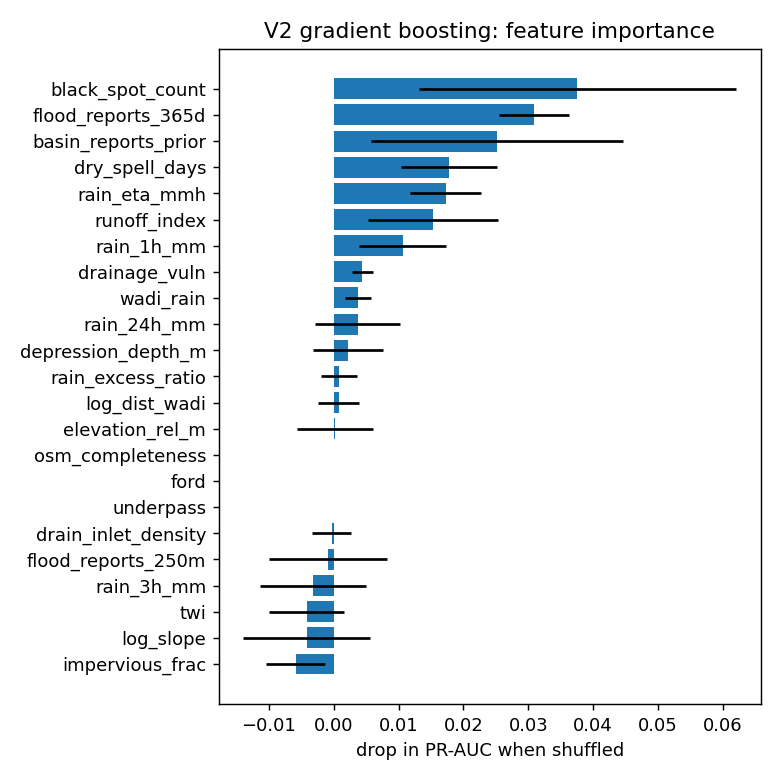

In [11]:
display(Image("reports/nyc/importance.png", width=460))

## 8. Transfert vers Nabeul (22 septembre 2018)

Les modèles new-yorkais sont appliqués sans modification. Les étiquettes viennent de cartes satellite faites après l'orage : elles montrent où l'eau s'est étendue.

In [12]:
nab = pd.read_csv("data/inventory_nabeul.csv")
yn = nab[LABEL].to_numpy()
print(f"segments : {len(nab):,} | inondés : {yn.sum()} ({yn.mean():.1%})")
print(nab.groupby("aoi").agg(segments=(LABEL, "size"), inondes=(LABEL, "sum"), pluie_totale=("storm_total_mm", "first"),
                             pic_mmh=("rain_eta_mmh", "first")).round(1))
pd.read_csv("reports/nabeul/transfer_metrics.csv", index_col=0)[["ROC-AUC", "PR-AUC", "base rate", "recall top 10%"]].round(3)

segments : 35,449 | inondés : 184 (0.5%)
                   segments  inondes  pluie_totale  pic_mmh
aoi                                                        
01TAKLISAH             2607        6          86.1     11.0
02MANZILBUZALAFAH     11978       73          30.2      3.4
03KORBA                8649       34          14.7      2.5
04BOUARGOUB            4734        0          13.9      1.7
05SOMAA                7481       71          17.0      6.1


,ROC-AUC,PR-AUC,base rate,recall top 10%
model,,,,
V1 multi-criteria,0.650,0.007,0.005,0.038
V2 gradient boosting,0.521,0.005,0.005,0.098
V2 logistic,0.371,0.004,0.005,0.005


### Susceptibilité relative : ce qui se transfère

Le modèle appris à New York reflète des inondations **urbaines**. À Nabeul, les inondations cartographiées sont des **crues éclair** sur des plaines. On compare :

- des modèles de terrain appris à New York (valeurs brutes ou percentiles dans la zone) ;
- V1 ;
- la **susceptibilité relative** (`v1.relative_susceptibility`) : segment bas et proche d'un cours d'eau, en percentiles dans la zone.

In [13]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
TERRAIN = ["elevation_rel_m", "twi", "depression_depth_m", "slope_pct", "impervious_frac", "dist_wadi_m"]
seg = inv.groupby("segment_id").agg({**{c: "first" for c in TERRAIN}, LABEL: "max"}).reset_index()
pct = lambda df, g: pd.DataFrame({c: (df.groupby(g)[c] if g else df[c]).rank(pct=True) for c in TERRAIN})
rows = []
for name, (Xs, Xt) in {"valeurs brutes": (seg[TERRAIN], nab[TERRAIN]),
                       "percentiles dans la zone": (pct(seg, None), pct(nab, "aoi"))}.items():
    for mname, model in [("GB", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05)),
                         ("logistique", LogisticRegression(max_iter=2000))]:
        p = model.fit(Xs, seg[LABEL]).predict_proba(Xt)[:, 1]
        rows.append({"méthode": f"terrain NYC, {name}, {mname}", "ROC-AUC Nabeul": roc_auc_score(yn, p),
                     "PR-AUC Nabeul": average_precision_score(yn, p)})
for name, p in [("V1 pondéré", v1.score(nab)), ("susceptibilité relative", v1.relative_susceptibility(nab, "aoi"))]:
    rows.append({"méthode": name, "ROC-AUC Nabeul": roc_auc_score(yn, p), "PR-AUC Nabeul": average_precision_score(yn, p)})
print(f"hasard : ROC-AUC 0.5, PR-AUC {yn.mean():.4f}")
pd.DataFrame(rows).set_index("méthode").round(3)

hasard : ROC-AUC 0.5, PR-AUC 0.0052


,ROC-AUC Nabeul,PR-AUC Nabeul
méthode,,
"terrain NYC, valeurs brutes, GB",0.310,0.004
"terrain NYC, valeurs brutes, logistique",0.384,0.004
"terrain NYC, percentiles dans la zone, GB",0.358,0.004
"terrain NYC, percentiles dans la zone, logistique",0.431,0.004
V1 pondéré,0.650,0.007
susceptibilité relative,0.800,0.025


In [14]:
rows = []
for aoi, d in nab.groupby("aoi"):
    if d[LABEL].sum() == 0:
        continue
    rows.append({"zone": aoi, "inondés": int(d[LABEL].sum()),
                 "susceptibilité relative": roc_auc_score(d[LABEL], v1.relative_susceptibility(d)),
                 "altitude relative seule": roc_auc_score(d[LABEL], -d.elevation_rel_m),
                 "distance à l'eau seule": roc_auc_score(d[LABEL], -d.dist_wadi_m),
                 "V1": roc_auc_score(d[LABEL], v1.score(d))})
s_nyc = inv.groupby("segment_id").agg(flooded=(LABEL, "max"), elevation_rel_m=("elevation_rel_m", "first"),
                                      dist_wadi_m=("dist_wadi_m", "first"))
rows.append({"zone": "New York (tous orages)", "inondés": int(s_nyc.flooded.sum()),
             "susceptibilité relative": roc_auc_score(s_nyc.flooded, v1.relative_susceptibility(s_nyc)),
             "altitude relative seule": roc_auc_score(s_nyc.flooded, -s_nyc.elevation_rel_m),
             "distance à l'eau seule": roc_auc_score(s_nyc.flooded, -s_nyc.dist_wadi_m), "V1": np.nan})
pd.DataFrame(rows).set_index("zone").round(3)

,inondés,susceptibilité relative,altitude relative seule,distance à l'eau seule,V1
zone,,,,,
01TAKLISAH,6,0.988,0.821,0.988,0.731
02MANZILBUZALAFAH,73,0.938,0.967,0.712,0.680
03KORBA,34,0.833,0.878,0.600,0.845
05SOMAA,71,0.636,0.494,0.692,0.307
New York (tous orages),650,0.476,0.561,0.398,NaN


In [15]:
fig, ax = plt.subplots(figsize=(6, 4.5))
b = __import__("joblib").load("models/nyc/v2_hgb.joblib")
for name, p in [("V2 GB (New York)", b.predict_proba(nab)), ("V1 pondéré", v1.score(nab)),
                ("susceptibilité relative", v1.relative_susceptibility(nab, "aoi"))]:
    fpr, tpr, _ = roc_curve(yn, p); ax.plot(fpr, tpr, label=f"{name} ({roc_auc_score(yn, p):.2f})")
ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set(title="ROC à Nabeul", xlabel="faux positifs", ylabel="rappel")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 9. Analyse des résultats

**Ce qui a changé par rapport à la première version réelle**

| | Première version | Version optimisée |
|---|---|---|
| Orages | 72 (≥ 30 mm, pluie ERA5) | 163 (≥ 15 mm, pluie mesurée) |
| ROC-AUC de V2 | 0,75 | **0,84** |
| PR-AUC rapportée au hasard | × 34 | **× 51** |
| Inondations couvertes en alertant 1 % des segments | 20 % | **28 %** |
| … 5 % des segments | 39 % | **51 %** |
| … 10 % des segments | 47 % | **63 %** |

Les deux versions ne portent pas exactement sur les mêmes orages (seuils différents) : la comparaison est indicative.

**1. V2 optimisé dépasse nettement V1.** ROC-AUC 0,84 contre 0,65. En alertant sur 2 % des segments-orages, V2 couvre 37 % des inondations, V1 10 %.

**2. Les fausses alertes restent structurelles.** Seules 0,055 % des lignes sont inondées. En alertant sur 2 % des lignes, au mieux 2,75 % des alertes peuvent être justes : même un modèle parfait aurait au moins 97 % de fausses alertes. L'objectif « ≤ 40 % de fausses alertes » du cahier des charges n'est pas atteignable à la granularité segment × orage ; il faut le redéfinir (par exemple : part des inondations couvertes pour un budget d'alertes, ou alerte par trajet plutôt que par segment).

**3. L'optimisation est stable.** Un apprentissage plus lent (taux 0,03) l'emporte sur 0,08 ; les meilleures combinaisons ne diffèrent que de moins de 0,002 de PR-AUC, le modèle ne dépend donc pas d'un réglage fragile.

**4. L'historique local porte l'essentiel.** Sans lui, la PR-AUC passe de 0,0386 à 0,0274 et la couverture à 2 % de 38 % à 28 %, dans les 4 plis. Les segments inondés ont eu 46 fois plus de signalements dans l'année précédente.

**5. L'hypothèse drainage est confirmée à New York.** Les segments inondés ont 8,6 fois plus de signalements « avaloir bouché » avant l'orage, et retirer cette variable fait baisser le score **dans les 4 plis** (ROC-AUC 0,846 → 0,819). En revanche, le **nombre** d'avaloirs n'aide pas : c'est leur **état** qui compte. Sans drainage **ni** historique, le modèle s'effondre (PR-AUC 0,004) : les deux portent une information commune (les avaloirs bouchés se trouvent là où l'eau revient).

**6. La pluie mesurée aide, la pluie ERA5 n'aidait pas.** Retirer la pluie baisse la PR-AUC dans 3 plis sur 4. Le pic horaire mesuré reste faiblement lié au nombre de segments inondés (Spearman 0,30) : la pluie dit *quand*, l'historique et le drainage disent *où*.

**7. Transfert à Nabeul : deux régimes d'inondation.** Les modèles new-yorkais, même limités au terrain, échouent à Nabeul (ROC-AUC 0,31 à 0,52) : ils ont appris des inondations **urbaines**. La **susceptibilité relative** (segment bas et proche d'un cours d'eau, en percentiles dans la zone) atteint **0,80** au total (PR-AUC 0,025, soit 5 fois le hasard) et 0,64 à 0,99 selon la zone. Elle ne marche pas à New York (0,48). Elle a été choisie après avoir regardé Nabeul : il faut la confirmer sur un autre événement tunisien avant de s'y fier.

**Recommandation pour la Tunisie.** Combiner deux composantes, modulées par la pluie prévue :
- **crues éclair** (plaines, oueds) : la susceptibilité relative, sans apprentissage, disponible partout ;
- **inondations urbaines** : un modèle V2 appris sur l'historique local et sur les signalements « avaloir bouché » de l'application (FR-21), dès que ces données existent.

## 10. Limites : corrigées et restantes

| Limite | Statut |
|---|---|
| Pluie ERA5 grossière | **Corrigée à New York** : pluie mesurée à JFK et LaGuardia, interpolée par segment. **Restante à Nabeul** : aucune pluie horaire mesurée ouverte ; l'analyse ECMWF IFS donne 14 à 86 mm contre environ 200 mm rapportés |
| DEM de surface (bâtiments) | **Corrigée à New York** : terrain nu USGS 3DEP 10 m. Nabeul : Copernicus 30 m avec ouverture morphologique |
| Avaloirs absents d'OpenStreetMap | **Corrigée à New York** : 154 212 avaloirs officiels (21 628 dans la zone). Absents à Nabeul |
| Seuil d'orage 30 mm imposé par la mémoire | **Corrigée** : 15 mm, 163 orages |
| Hyperparamètres fixés à la main | **Corrigée** : recherche par validation croisée par orage |
| Seuil High à 70 % de rappel inutilisable | **Corrigée** : niveaux par budget d'alertes (`--levels budget`) |
| Ablation mélangeant drainage et historique | **Corrigée** : groupes séparés |
| Transfert vers Nabeul | **Partielle** : susceptibilité relative 0,80, à confirmer sur un autre événement |
| Sous-échantillonnage des non-inondés | Choix de calcul, compensé par la correction des probabilités ; l'évaluation utilise toutes les lignes |
| Étiquettes 311 (biais de déclaration, heure imprécise) | **Restante** |
| Un seul événement tunisien | **Restante** : il faut un inventaire tunisien (presse, protection civile, signalements) |
| Fausses alertes ≥ 97 % au niveau segment × orage | **Restante, structurelle** : l'objectif doit être redéfini |